## 线性回归预测房价
任务：基于usa housing price.csv数据，建立线性回归模型，预测合理房价：

    1、以面积为输入变量，建立单因子模型，评估模型表现，可视化线性回归预测结果
    2、以income、house age、numbers of rooms、population、area为输入变量，建立多因子模型，评估模型表现
    3、預測Income=65000, House Age=5, Number of Rooms=5, Population=30000,size=200的合理房价

In [1]:
# load the data
import pandas as pd
import numpy as np
data = pd.read_csv('usa_housing_price.csv')
data.head()

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Area Population,size,Price
0,79545.45857,5.317139,7.009188,23086.80050,188.214212,1.059034e+06
1,79248.64245,4.997100,6.730821,40173.07217,160.042526,1.505891e+06
2,61287.06718,5.134110,8.512727,36882.15940,227.273545,1.058988e+06
3,63345.24005,3.811764,5.586729,34310.24283,164.816630,1.260617e+06
4,59982.19723,5.959445,7.839388,26354.10947,161.966659,6.309435e+05


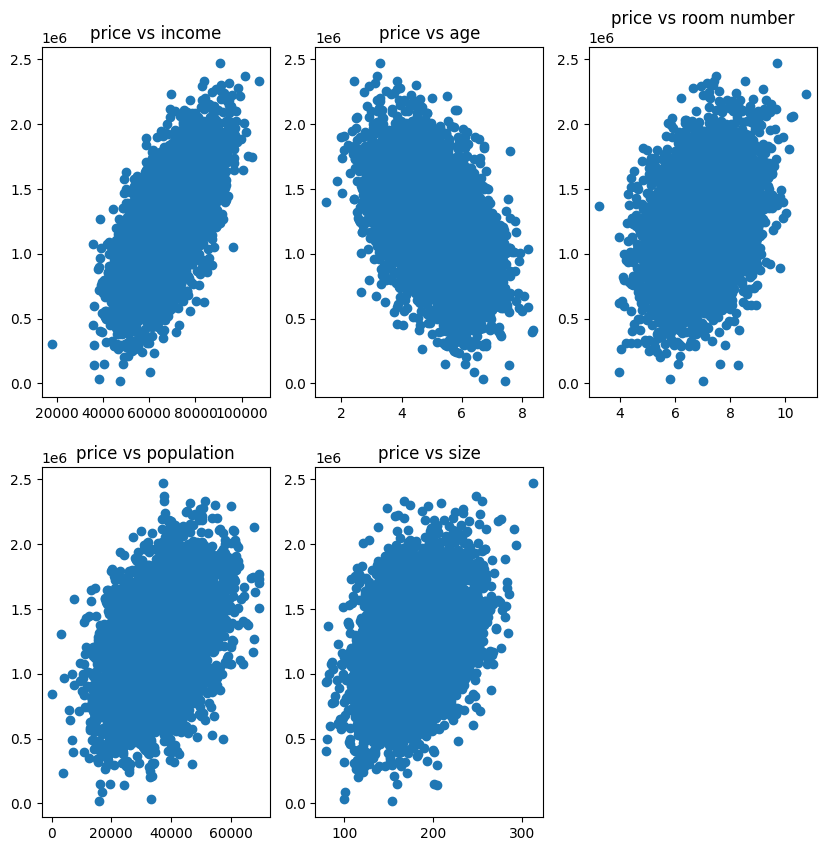

In [2]:
from matplotlib import pyplot as plt
fig = plt.figure(figsize=(10,10))
fig1 = plt.subplot(231)
plt.scatter(data.loc[:,'Avg. Area Income'],data.loc[:,'Price'])
plt.title('price vs income')

fig2 = plt.subplot(232)
plt.scatter(data.loc[:,'Avg. Area House Age'],data.loc[:,'Price'])
plt.title('price vs age')

fig3 = plt.subplot(233)
plt.scatter(data.loc[:,'Avg. Area Number of Rooms'],data.loc[:,'Price'])
plt.title('price vs room number')

fig4 = plt.subplot(234)
plt.scatter(data.loc[:,'Area Population'],data.loc[:,'Price'])
plt.title('price vs population')

fig5 = plt.subplot(235)
plt.scatter(data.loc[:,'size'],data.loc[:,'Price'])
plt.title('price vs size')

plt.show()

In [3]:
# define x and y
x = data.loc[:,'size']
y = data.loc[:,'Price']
x = np.array(x)
x = x.reshape(-1,1)
y = np.array(y)
y = y.reshape(-1,1)

In [4]:
# set up linear regussion model
from sklearn.linear_model import LinearRegression 
lr1 = LinearRegression()
# train the model
lr1.fit(x,y)

LinearRegression()

In [5]:
# calculate the price with the size
y_predict1 = lr1.predict(x)
print(y_predict1)

[[1276881.85636623]
 [1173363.58767144]
 [1420407.32457443]
 ...
 [1097848.86467426]
 [1264502.88144558]
 [1131278.58816273]]


In [6]:

#评估模型
from sklearn.metrics import mean_squared_error,r2_score
MSE1 = mean_squared_error(y,y_predict1)
R21 = r2_score(y,y_predict1)
print(MSE1,R21)

108771672553.6264 0.1275031240418234


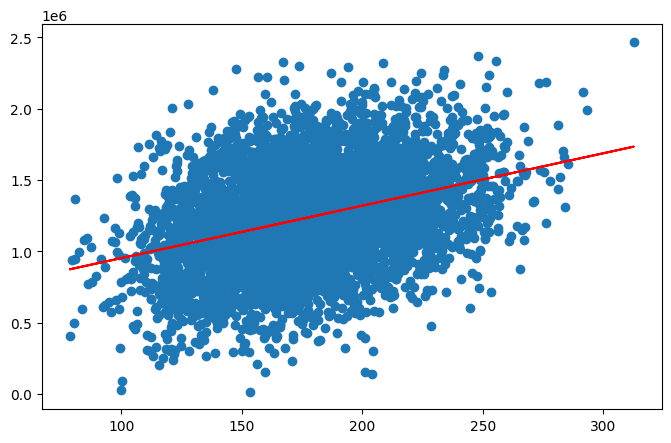

In [7]:
fig6 = plt.figure(figsize=(8,5))
plt.scatter(x,y)
# x轴是size，Y轴是新预测的结果，红色标示线
plt.plot(x,y_predict1,'r')
plt.show()

In [8]:
# define x_multi
# 将变量X变为多因子，以提高模型准确率，去掉最后的price（预测目标）
x_multi = data.drop(['Price'],axis=1)
x_multi

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Area Population,size
0,79545.45857,5.317139,7.009188,23086.80050,188.214212
1,79248.64245,4.997100,6.730821,40173.07217,160.042526
2,61287.06718,5.134110,8.512727,36882.15940,227.273545
3,63345.24005,3.811764,5.586729,34310.24283,164.816630
4,59982.19723,5.959445,7.839388,26354.10947,161.966659
...,...,...,...,...,...
4995,60567.94414,3.169638,6.137356,22837.36103,161.641403
4996,78491.27543,4.000865,6.576763,25616.11549,159.164596
4997,63390.68689,3.749409,4.805081,33266.14549,139.491785
4998,68001.33124,5.465612,7.130144,42625.62016,184.845371


In [9]:
# set up multi leaner model
lr2 = LinearRegression()
lr2.fit(x_multi,y)

LinearRegression()

In [10]:
y_predict2 = lr2.predict(x_multi)
print(y_predict2)

[[1223968.89166039]
 [1497306.33188643]
 [1250884.31019441]
 ...
 [1020693.92390366]
 [1260503.36914608]
 [1302737.79157666]]


In [11]:
# 评估结果
MSE2 = mean_squared_error(y,y_predict2)
R22 = r2_score(y,y_predict2)
print(MSE2,R22)

10219846512.17786 0.9180229195220739


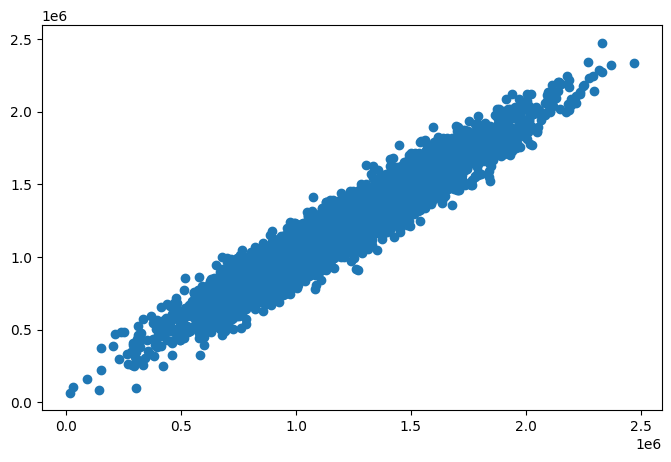

In [12]:
# 可视化模型结果
# 因为是多因子，所以无法直观的画出，所以通过比较预测Y和原Y的差距来观测
# X轴是原Y，Y轴是预测Y。当预测Y约靠近原Y，那么就是越趋近于x=y的函数，是一条和坐标轴夹角45度的直线，也就是预测结果越准
fig7 = plt.figure(figsize=(8,5))
plt.scatter(y,y_predict2)
plt.show()

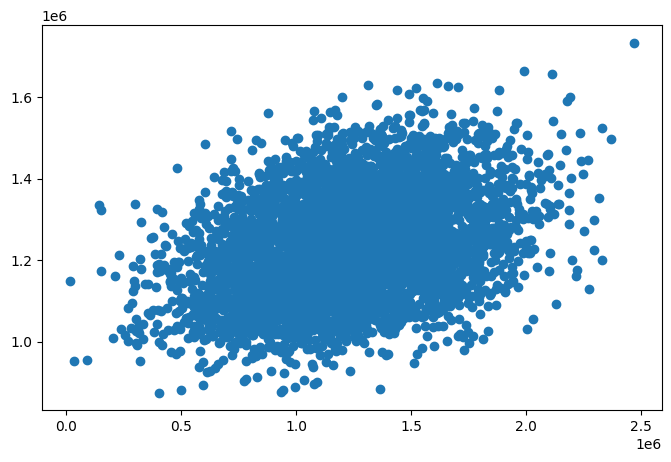

In [13]:
# 与单因子做个对比
fig8 = plt.figure(figsize=(8,5))
plt.scatter(y,y_predict1)
plt.show()

In [15]:
# 预测价格
x_test = [[65000,5, 5, 30000,200]]
print(x_test)
y_predictx = lr2.predict(x_test)
print(y_predictx)

[[65000, 5, 5, 30000, 200]]
[[817052.19516277]]


/Users/liuyide/anaconda3/envs/ai_tec/lib/python3.11/site-packages/sklearn/base.py:464: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
